<!-- DOC-BANNER -->
# FunctionTransformer — Log Transform and Friends (Day 30)

> **Playlist:** CampusX Day 30 *Function Transformer | Log Transform | Reciprocal | Square Root* (and Day 31 Power/Box-Cox/Yeo-Johnson) — **beyond your Video-29 boundary**. Studied with code and execution outputs; detailed notes pending.
> **Status:** STUDIED — real experiments (normality checks via distplot/QQ-plot/skew, `log1p` on Fare, LogReg vs Tree before/after, ColumnTransformer integration, `cross_val_score`, `apply_transform` helper) with executed outputs. Box-Cox/Yeo-Johnson still to deepen; `topic_notes.md` not written yet.
> **Prerequisites (when you get there):** skewed distributions, `FunctionTransformer`/`PowerTransformer` API, train-only fitting.


# FUNCTION TRANSFRORMER 


## log trans
## reciprocal
## power(sq/sqrt)

## box -cox 
## yeo johson


## some algo perform bwtter with the normal data so try to convert the data into the normal distribution  


## how to know  ifd the given data is normal or not 


##  3 WAYS 
   
##   sns.distplot 
   
##   QQplot
   
##    pd.skew

##  if data is normally distributed them in QQplot linwe is is 45 degreee 

# LOG TRANSFORM

## dont use on negative values
## used  in right skewed data 
## boils down the scale highly 



# other transforms 

## reciprocal 
## square  
## square root 

In [ ]:
import numpy as np 
import pandas as pd 


import scipy .stats as stats 
import matplotlib.pyplot as plt 
import seaborn as sns 

from sklearn.model_selection import train_test_split 
from  sklearn.metrics import accuracy_score
from sklearn.model_selection import  cross_val_score 




from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier


from sklearn.preprocessing import FunctionTransformer
from  sklearn.compose import ColumnTransformer 


In [ ]:
df = pd.read_csv(r"E:\MACHINE_LEARNING\DATA_SETS\train.csv")

df = df[['Survived' ,'Age', 'Fare' ]]

df['Age'] = df['Age'].fillna(df['Age'].mean())

X = df.iloc[: , 1 : 3 ]
y =df.iloc[: , 0 ]


In [ ]:
X_train ,X_test , y_train , y_test = train_test_split(X  , y , test_size = .2 ,     random_state =  34)


C:\Users\saumi\AppData\Local\Temp\ipykernel_5664\1324837531.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(X_train['Age'])


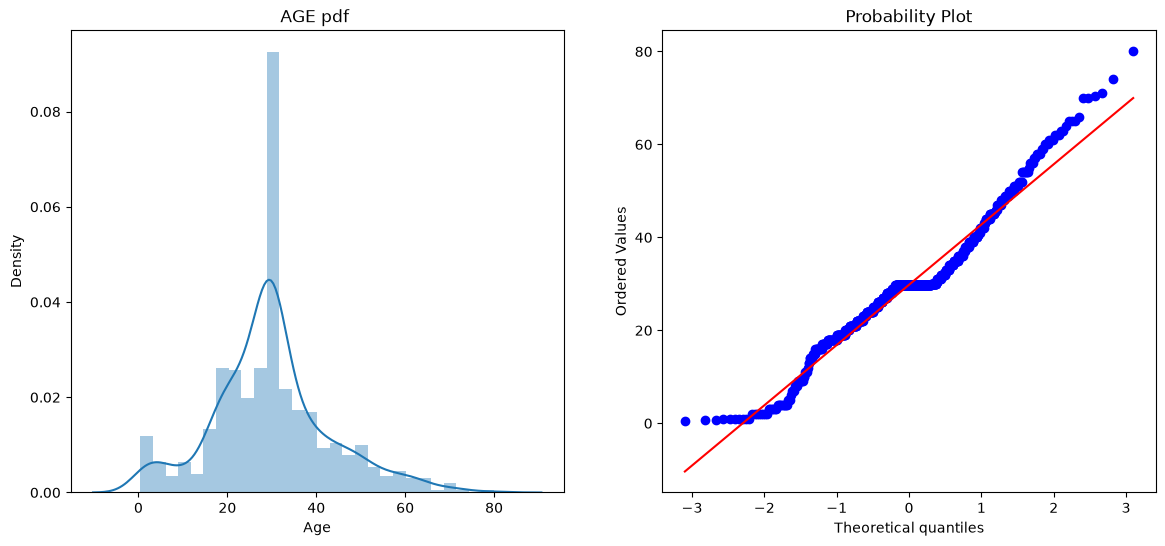

In [87]:
plt.figure(figsize = (14 , 6) )
plt.subplot(121)
sns.distplot(X_train['Age'])

plt.title('AGE pdf ')

plt.subplot(122)
stats.probplot( X_train['Age'] , dist="norm" , plot =  plt )

plt.show()

C:\Users\saumi\AppData\Local\Temp\ipykernel_5664\298171780.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(X_train['Fare'])


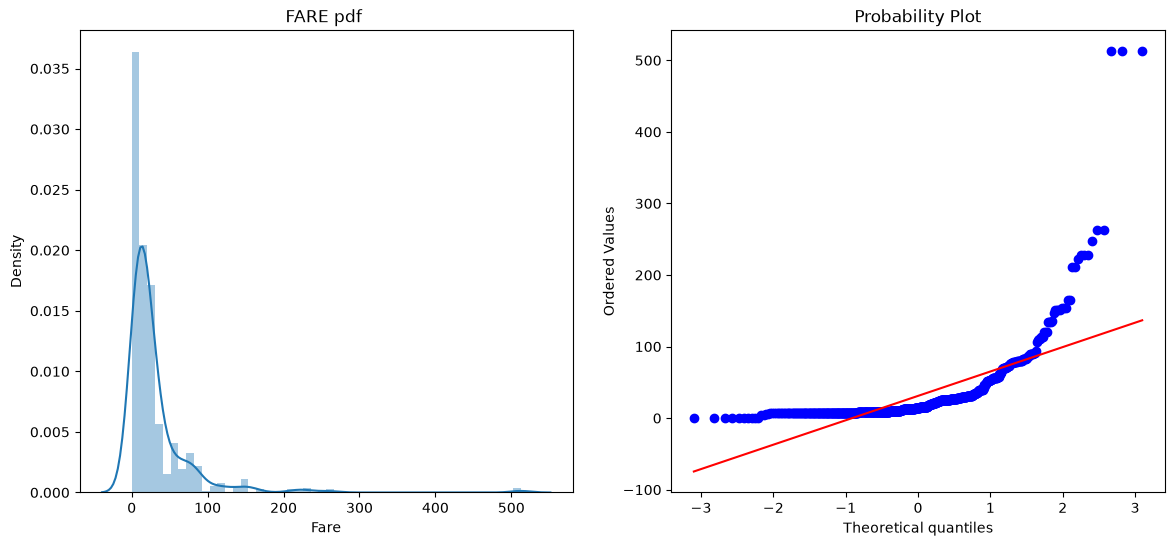

In [88]:
plt.figure(figsize = (14 , 6) )
plt.subplot(121)
sns.distplot(X_train['Fare'])

plt.title('FARE pdf ')

plt.subplot(122)
stats.probplot( X_train['Fare'] , dist="norm" , plot =  plt )

plt.show()

In [89]:
clf = LogisticRegression()

clf2 = DecisionTreeClassifier()

In [109]:
clf.fit(X_train , y_train)
clf2.fit( X_train , y_train)

y_pred = clf.predict(X_test)
y_pred1 = clf2.predict(X_test)



print("Accuracy LR" , accuracy_score (y_test , y_pred))
print("Accuracy DT" , accuracy_score(y_test , y_pred1))



 

Accuracy LR 0.7206703910614525
Accuracy DT 0.6815642458100558


In [91]:
trf = FunctionTransformer(func= np.log1p)

In [96]:
X_train_trans = trf.fit_transform(X_train)

X_test_trans = trf.fit_transform(X_test)


In [97]:
clf = LogisticRegression()

clf2 = DecisionTreeClassifier()

In [105]:
clf.fit(X_train_trans , y_train)
clf2.fit( X_train_trans , y_train)

y_pred = clf.predict(X_test_trans)
y_pred1 = clf2.predict(X_test_trans)



print("Accuracy LR" , accuracy_score (y_test , y_pred))
print("Accuracy DT" , accuracy_score(y_test , y_pred1))



 

Accuracy LR 0.7374301675977654
Accuracy DT 0.7094972067039106


In [113]:
X_transf = trf.fit_transform(X)


clf = LogisticRegression()

clf2 = DecisionTreeClassifier()

print("LR",np.mean(cross_val_score(clf , X_transf , y , scoring = 'accuracy' ,cv= 15)))

print("DT" , np.mean(cross_val_score(clf2 , X_transf , y , scoring = 'accuracy' ,cv= 15)))

LR 0.6770056497175143
DT 0.6621092278719396


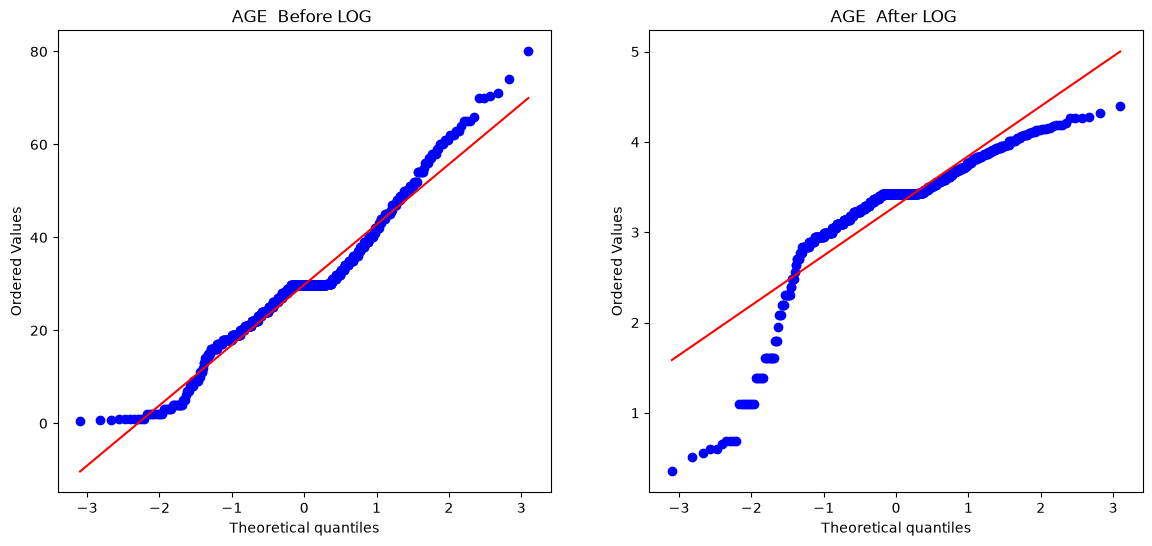

In [114]:

plt.figure(figsize = (14 , 6) )
plt.subplot(121)
stats.probplot( X_train['Age'] , dist="norm" , plot =  plt )

plt.title(' AGE  Before LOG  ')

plt.subplot(122)
stats.probplot( X_train_trans['Age'] , dist="norm" , plot =  plt )

plt.title(' AGE  After LOG  ')

plt.show()

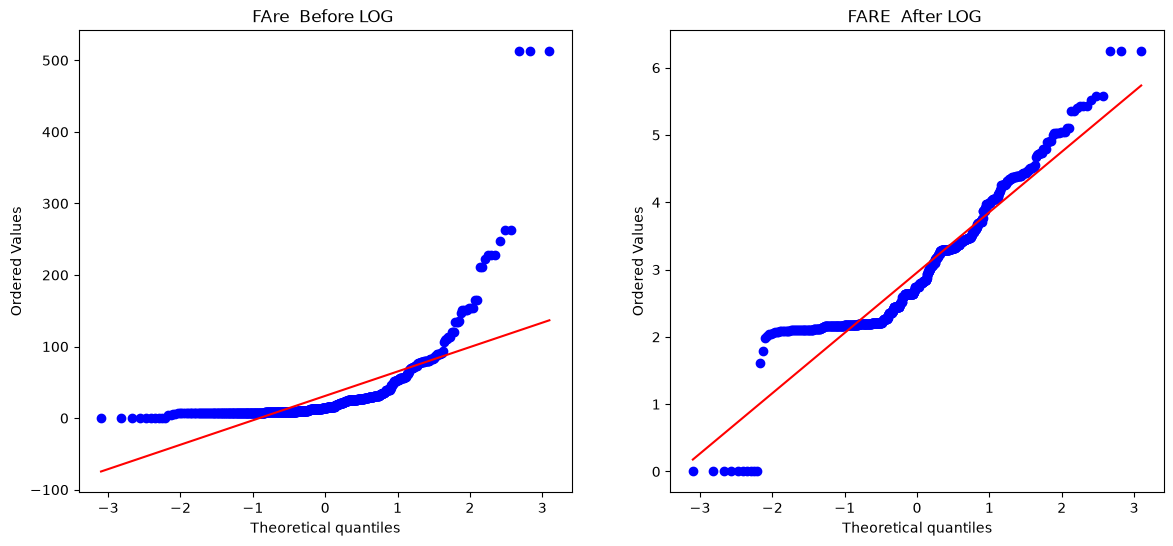

In [115]:

plt.figure(figsize = (14 , 6) )
plt.subplot(121)
stats.probplot( X_train['Fare'] , dist="norm" , plot =  plt )

plt.title(' FAre  Before LOG  ')

plt.subplot(122)
stats.probplot( X_train_trans['Fare'] , dist="norm" , plot =  plt )

plt.title(' FARE  After LOG  ')

plt.show()

In [116]:
trf2 = ColumnTransformer([('log' , FunctionTransformer(np.log1p) , ['Fare'])] , remainder= 'passthrough')


X_train_trans2 = trf2.fit_transform(X_train)

X_test_trans2 = trf2.transform(X_test)


clf = LogisticRegression()

clf2 = DecisionTreeClassifier()


clf.fit(X_train_trans2 , y_train)
clf2.fit( X_train_trans2 , y_train)

y_pred = clf.predict(X_test_trans2)
y_pred1 = clf2.predict(X_test_trans2)



print("Accuracy LR" , accuracy_score (y_test , y_pred))
print("Accuracy DT" , accuracy_score(y_test , y_pred1))





Accuracy LR 0.7150837988826816
Accuracy DT 0.7039106145251397


In [117]:
X_transf = trf2.fit_transform(X)


clf = LogisticRegression()

clf2 = DecisionTreeClassifier()

print("LR",np.mean(cross_val_score(clf , X_transf , y , scoring = 'accuracy' ,cv= 15)))

print("DT" , np.mean(cross_val_score(clf , X_transf , y , scoring = 'accuracy' ,cv= 15)))

LR 0.6679472693032015
DT 0.6679472693032015


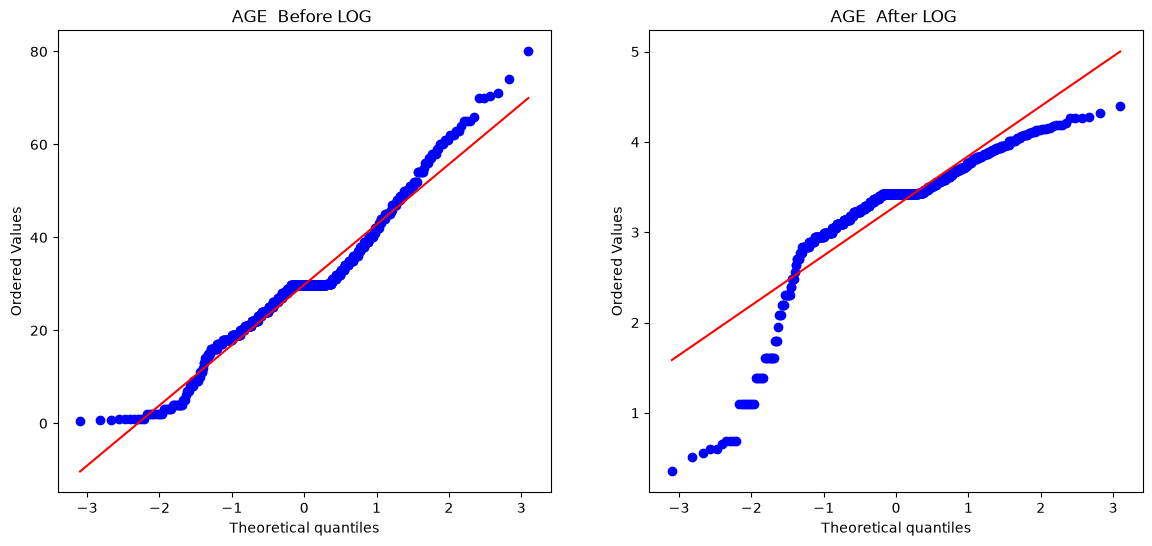

In [118]:

plt.figure(figsize = (14 , 6) )
plt.subplot(121)
stats.probplot( X_train['Age'] , dist="norm" , plot =  plt )

plt.title(' AGE  Before LOG  ')

plt.subplot(122)
stats.probplot( X_train_trans['Age'] , dist="norm" , plot =  plt )

plt.title(' AGE  After LOG  ')

plt.show()

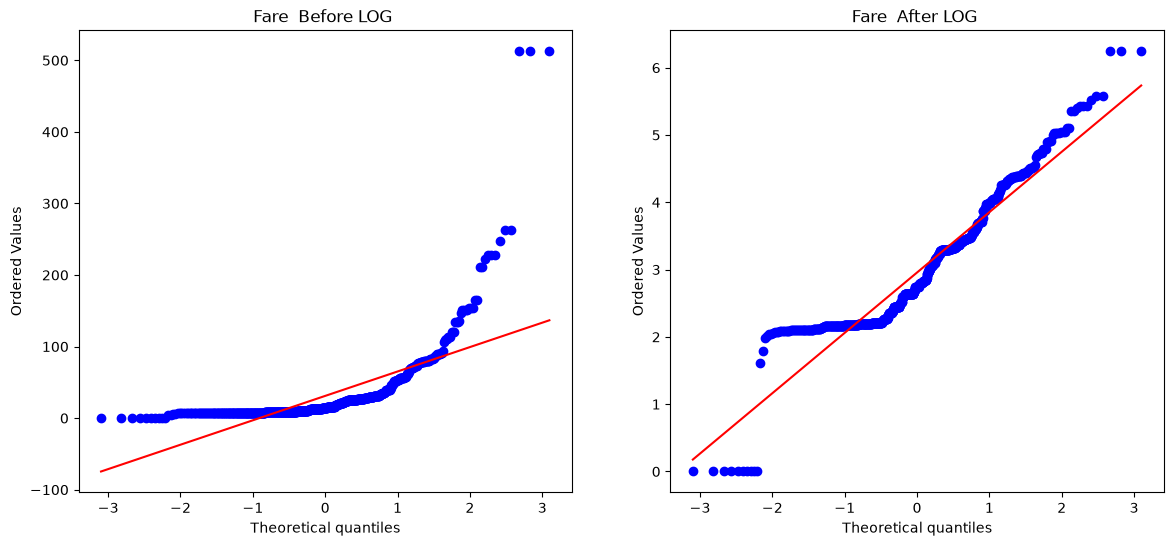

In [119]:

plt.figure(figsize = (14 , 6) )
plt.subplot(121)
stats.probplot( X_train['Fare'] , dist="norm" , plot =  plt )

plt.title(' Fare  Before LOG  ')

plt.subplot(122)
stats.probplot( X_train_trans['Fare'] , dist="norm" , plot =  plt )

plt.title(' Fare  After LOG  ')

plt.show()

In [133]:
def apply_transform(transform):

    X = df[['Age', 'Fare']]
    y = df['Survived']

    trf = ColumnTransformer(
        [('log', FunctionTransformer(transform), ['Fare'])],
        remainder='passthrough'
    )

    X_trans = trf.fit_transform(X)
    clf = LogisticRegression()

    print("Accuracy", np.mean(cross_val_score(
        clf, X_trans, y, scoring='accuracy', cv=15
    )))

    plt.figure(figsize=(14, 4))

    plt.subplot(121)
    stats.probplot(X['Fare'], dist='norm', plot=plt)
    plt.title('Fare Before Transform')

    plt.subplot(122)
    stats.probplot(X_trans[:, 0], dist='norm', plot=plt)
    plt.title('Fare After Transform')

    plt.show()

Accuracy 0.6184557438794727


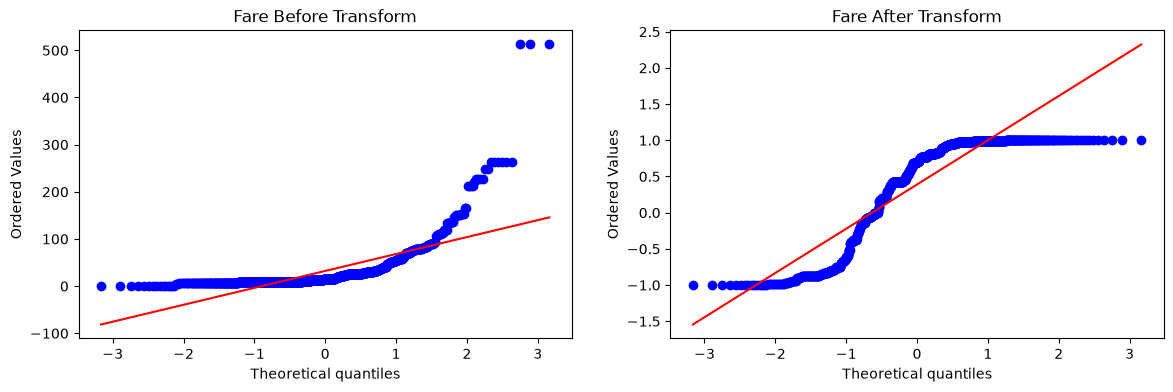

In [145]:
apply_transform(np.sin)

<!-- DOC-BANNER -->
## Key takeaways (studied with code)
- Idea: some algorithms prefer near-normal features → try log/reciprocal/sqrt, then Box-Cox (positive-only) / Yeo-Johnson (any sign).
- Code + outputs present (log1p demo, model comparison, `apply_transform` helper). Still open: `topic_notes.md`, Box-Cox/Yeo-Johnson.
